# 02 · Peak annotation and RNA-seq integration

Annotates the DiffBind consensus sites from `01_diffbind.ipynb` against the **same Ensembl 114 GRCm39 GTF** used by the RNA-seq,
then links differential binding to the RNA-seq `cr_vs_hfd` DESeq2 results.

* **Nearest gene** = nearest protein-coding transcript TSS to the site centre (summit), with a strand-aware signed distance
  (negative = upstream).
* **Genomic feature**, assigned to the site centre by priority: Promoter (±3 kb of a TSS) > 5′ UTR > 3′ UTR > Exon > Intron > Intergenic.
* Directions: positive `Fold` = higher binding in CR; positive `log2FoldChange` = higher expression in CR.

Kernel: `Python (hnr chipseq)`. Run from `chipseq-workflow/analysis/` after notebook 01. Outputs go to `../results/downstream/annotation/`.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import pyranges as pr
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import fisher_exact, spearmanr

DB_DIR = Path("../results/downstream/diffbind")
OUT = Path("../results/downstream/annotation"); OUT.mkdir(parents=True, exist_ok=True)
GTF = Path("../../resources/genome.gtf")
RNA = Path("../../results/diffexp/cr_vs_hfd.diffexp.tsv")
HOMER = Path("../results/bwa/merged_library/macs3/narrow_peak/consensus")
PEAKS = Path("../results/bwa/merged_library/macs3/narrow_peak")

FACTORS = ["PPARA", "RXRA"]
FDR_TH, PROMOTER, LINK_DIST = 0.05, 3000, 10_000
MAIN_CHR = [str(i) for i in range(1, 20)] + ["X", "Y"]

# Reference palette slots 1-2 (validated adjacent pair) + neutral grey for non-significant
C_CR, C_HFD, C_NS = "#2a78d6", "#eb6834", "#b4b2a9"
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b"})

## Gene model from the GTF
Parses only `transcript`, `exon` and UTR rows of the 1.1 GB GTF once and caches them.

In [2]:
cache = OUT / "gtf_features.pkl"
if cache.exists():
    gtf = pd.read_pickle(cache)
else:
    keep = {"transcript", "exon", "five_prime_utr", "three_prime_utr"}
    chunks = []
    for ch in pd.read_csv(GTF, sep="\t", comment="#", header=None, usecols=[0, 2, 3, 4, 6, 8],
                          names=["Chromosome", "Feature", "Start", "End", "Strand", "attr"],
                          dtype={0: str}, chunksize=500_000):
        ch = ch[ch.Feature.isin(keep) & ch.Chromosome.isin(MAIN_CHR)]
        for key in ["gene_id", "gene_name", "gene_biotype", "transcript_biotype"]:
            ch[key] = ch.attr.str.extract(f'{key} "([^"]+)"', expand=False)
        chunks.append(ch.drop(columns="attr"))
    gtf = pd.concat(chunks, ignore_index=True)
    gtf["Start"] -= 1                                     # GTF 1-based closed -> 0-based half-open
    gtf["gene_name"] = gtf.gene_name.fillna(gtf.gene_id)
    gtf.to_pickle(cache)
gtf.Feature.value_counts()

Feature
exon               1298672
transcript          278262
five_prime_utr       95668
three_prime_utr      87170
Name: count, dtype: int64

In [3]:
tx = gtf[(gtf.Feature == "transcript") & (gtf.transcript_biotype == "protein_coding")].copy()
tx["tss"] = np.where(tx.Strand == "+", tx.Start, tx.End - 1)
tss = tx.drop_duplicates(["Chromosome", "tss", "gene_id"])[["Chromosome", "tss", "Strand", "gene_id", "gene_name"]]
tss_gr = pr.PyRanges(tss.assign(Start=tss.tss, End=tss.tss + 1).rename(columns={"Strand": "gene_strand"}))

feature_gr = {
    "5' UTR": pr.PyRanges(gtf[gtf.Feature == "five_prime_utr"][["Chromosome", "Start", "End"]]),
    "3' UTR": pr.PyRanges(gtf[gtf.Feature == "three_prime_utr"][["Chromosome", "Start", "End"]]),
    "Exon":   pr.PyRanges(gtf[gtf.Feature == "exon"][["Chromosome", "Start", "End"]]),
    "Intron": pr.PyRanges(gtf[gtf.Feature == "transcript"][["Chromosome", "Start", "End"]]),  # gene body minus the above
}
FEATURE_ORDER = ["Promoter", "5' UTR", "3' UTR", "Exon", "Intron", "Intergenic"]
print(f"{tss.gene_id.nunique():,} protein-coding genes, {len(tss):,} unique TSSs")

21,572 protein-coding genes, 54,176 unique TSSs


## Annotation function

In [4]:
def annotate(sites: pd.DataFrame) -> pd.DataFrame:
    """sites: needs site_id, chr, start, end (1-based closed, as exported by DiffBind)."""
    s = sites.copy()
    s["center"] = (s.start + s.end) // 2 - 1                   # 0-based summit position
    pts = pr.PyRanges(pd.DataFrame({"Chromosome": s.chr.astype(str), "Start": s.center,
                                    "End": s.center + 1, "site_id": s.site_id}))
    near = pts.nearest(tss_gr, strandedness=False).df[["site_id", "Start", "gene_id", "gene_name", "gene_strand", "tss"]]
    near = near.drop_duplicates("site_id")                        # ties: keep first
    sign = np.where(near.gene_strand == "+", 1, -1)
    near["dist_to_tss"] = (near.Start - near.tss) * sign
    s = s.merge(near.drop(columns=["Start", "gene_strand", "tss"]), on="site_id", how="left")

    s["feature"] = "Intergenic"
    for feat in ["Intron", "Exon", "3' UTR", "5' UTR"]:          # low -> high priority, later overwrites
        hit = set(pts.overlap(feature_gr[feat]).df.site_id) if len(pts) else set()
        s.loc[s.site_id.isin(hit), "feature"] = feat
    s.loc[s.dist_to_tss.abs() <= PROMOTER, "feature"] = "Promoter"
    s["feature"] = pd.Categorical(s.feature, FEATURE_ORDER, ordered=True)
    return s.drop(columns="center")

## Annotate DiffBind consensus sites

In [5]:
ann = {}
for f in FACTORS:
    db = pd.read_csv(DB_DIR / f"{f}.db_all.tsv", sep="\t", dtype={"chr": str})
    db = db[db.chr.isin(MAIN_CHR)]
    a = annotate(db)
    a["db_class"] = np.select([(a.FDR < FDR_TH) & (a.Fold > 0), (a.FDR < FDR_TH) & (a.Fold < 0)],
                              ["CR-gained", "HFD-gained"], "n.s.")
    ann[f] = a
    a.to_csv(OUT / f"{f}.consensus.annotated.tsv", sep="\t", index=False)
    a[a.db_class != "n.s."].to_csv(OUT / f"{f}.db_sig.annotated.tsv", sep="\t", index=False)

pd.concat({f: a.db_class.value_counts() for f, a in ann.items()}, axis=1).fillna(0).astype(int)

,PPARA,RXRA
db_class,,
n.s.,3265,11664


In [6]:
sets = {}
for f, a in ann.items():
    sets[f"{f} all"] = a
    for c in ["CR-gained", "HFD-gained"]:
        if (a.db_class == c).sum() >= 10:
            sets[f"{f} {c}"] = a[a.db_class == c]

dist = pd.DataFrame({k: v.feature.value_counts(normalize=True).reindex(FEATURE_ORDER) * 100 for k, v in sets.items()}).T
dist.insert(0, "n", [len(v) for v in sets.values()])
dist.round(1)

feature,n,Promoter,5' UTR,3' UTR,Exon,Intron,Intergenic
PPARA all,3265,19.0,0.0,1.4,6.5,51.9,21.1
RXRA all,11664,30.6,0.1,1.8,7.2,45.1,15.3


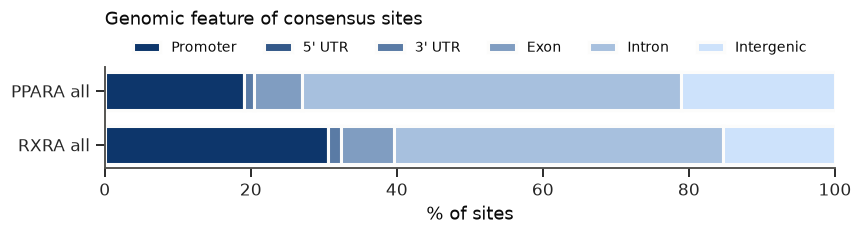

In [7]:
pal = sns.color_palette("blend:#0d366b,#cde2fb", n_colors=len(FEATURE_ORDER))   # one hue, ordinal categories
fig, ax = plt.subplots(figsize=(8, 0.55 * len(dist) + 1.2))
left = np.zeros(len(dist))
for feat, col in zip(FEATURE_ORDER, pal):
    ax.barh(dist.index, dist[feat], left=left, color=col, edgecolor="#fcfcfb", linewidth=2, label=feat, height=0.7)
    left += dist[feat].values
ax.invert_yaxis(); ax.set_xlabel("% of sites"); ax.set_xlim(0, 100)
ax.legend(ncol=len(FEATURE_ORDER), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=9)
ax.set_title("Genomic feature of consensus sites", pad=28, loc="left")
fig.tight_layout(); fig.savefig(OUT / "feature_distribution.png", dpi=200); plt.show()

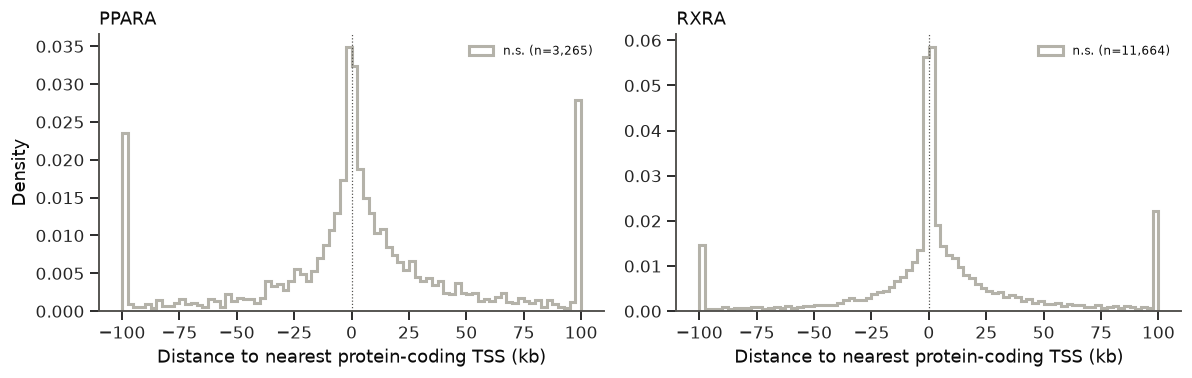

In [8]:
fig, axes = plt.subplots(1, len(FACTORS), figsize=(11, 3.6), sharey=False)
bins = np.linspace(-100, 100, 81)
for ax, f in zip(axes, FACTORS):
    a = ann[f]
    for cls, col in [("n.s.", C_NS), ("CR-gained", C_CR), ("HFD-gained", C_HFD)]:
        d = a.loc[a.db_class == cls, "dist_to_tss"].clip(-100_000, 100_000) / 1000
        if len(d):
            ax.hist(d, bins=bins, density=True, histtype="step", linewidth=2, color=col, label=f"{cls} (n={len(d):,})")
    ax.axvline(0, color="#52514e", lw=0.8, ls=":")
    ax.set_title(f, loc="left"); ax.set_xlabel("Distance to nearest protein-coding TSS (kb)")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Density")
fig.tight_layout(); fig.savefig(OUT / "distance_to_tss.png", dpi=200); plt.show()

### Sanity check against the pipeline's HOMER annotation
HOMER annotates the pipeline's own (un-recentred) consensus peaks and uses a narrower promoter (−1 kb to +100 bp) and
all gene biotypes, so values will differ somewhat. The ordering of categories should agree.

In [9]:
def homer_dist(f):
    h = pd.read_csv(HOMER / f / f"{f}.consensus_peaks.annotatePeaks.txt", sep="\t", usecols=["Annotation"])
    cat = h.Annotation.fillna("NA").str.replace(r"\s*\(.*", "", regex=True).str.strip()
    return cat.value_counts(normalize=True).mul(100).round(1)
pd.DataFrame({f"{f} HOMER": homer_dist(f) for f in FACTORS})

,PPARA HOMER,RXRA HOMER
Annotation,,
intron,48.1,45.2
promoter-TSS,20.3,25.7
Intergenic,20.1,15.8
TTS,7.0,7.1
exon,4.5,6.2
NA,0.1,0.0


## PPARα / RXRα co-occupancy
PPARα binds DNA as a heterodimer with RXRα, so a large share of PPARα sites should also be RXRα sites. Shown for the DiffBind consensus sets and, per diet, for the union of both replicates' MACS3 peaks.

In [10]:
def gr(df):
    return pr.PyRanges(pd.DataFrame({"Chromosome": df.chr.astype(str), "Start": df.start - 1, "End": df.end, "site_id": df.site_id}))

p_gr, r_gr = gr(ann["PPARA"]), gr(ann["RXRA"])
shared_p = set(p_gr.overlap(r_gr).df.site_id)
ann["PPARA"]["rxra_cobound"] = ann["PPARA"].site_id.isin(shared_p)
ann["RXRA"]["ppara_cobound"] = ann["RXRA"].site_id.isin(set(r_gr.overlap(p_gr).df.site_id))

def diet_union(factor, diet):
    dfs = [pd.read_csv(PEAKS / f"{diet}_{factor}_REP{r}_peaks.narrowPeak", sep="\t", header=None, usecols=[0, 1, 2],
                       names=["Chromosome", "Start", "End"], dtype={0: str}) for r in (1, 2)]
    return pr.PyRanges(pd.concat(dfs)).merge()

rows = [{"set": "consensus (DiffBind)", "PPARA": len(p_gr), "RXRA": len(r_gr),
         "PPARA overlapping RXRA": len(shared_p)}]
for diet in ["CR", "HFD"]:
    p, r = diet_union("PPARA", diet), diet_union("RXRA", diet)
    rows.append({"set": f"{diet} MACS3 union", "PPARA": len(p), "RXRA": len(r), "PPARA overlapping RXRA": len(p.overlap(r))})
co = pd.DataFrame(rows)
co["% PPARA co-bound"] = (100 * co["PPARA overlapping RXRA"] / co.PPARA).round(1)
co

,set,PPARA,RXRA,PPARA overlapping RXRA,% PPARA co-bound
0,consensus (DiffBind),3265,11664,2054,62.9
1,CR MACS3 union,3814,24260,2504,65.7
2,HFD MACS3 union,16142,28919,10547,65.3


In [11]:
pd.crosstab(ann["PPARA"].feature, ann["PPARA"].rxra_cobound.map({True: "RXRA co-bound", False: "PPARA only"}),
            normalize="columns").mul(100).round(1)

rxra_cobound,PPARA only,RXRA co-bound
feature,,
Promoter,15.9,20.8
5' UTR,0.0,0.0
3' UTR,1.0,1.7
Exon,5.6,7.0
Intron,53.3,51.1
Intergenic,24.2,19.3


## Enrichment of genes near differential sites
Enrichr (via gseapy) on the nearest protein-coding genes of sites within 10 kb of a TSS, with the genes near **any** consensus site of
that factor as background. Only gene symbols are sent to the Enrichr web service. Sets with < 20 genes are skipped.

In [12]:
import gseapy as gp
LIBS = ["GO_Biological_Process_2023", "KEGG_2019_Mouse"]

def near_genes(df):
    return sorted(set(df.loc[df.dist_to_tss.abs() <= LINK_DIST, "gene_name"].str.upper()))

enr = {}
for f, a in ann.items():
    bg = near_genes(a)
    for cls in ["CR-gained", "HFD-gained"]:
        genes = near_genes(a[a.db_class == cls])
        key = f"{f} {cls}"
        if len(genes) < 20:
            print(f"{key}: {len(genes)} genes, skipped"); continue
        try:
            r = gp.enrichr(gene_list=genes, gene_sets=LIBS, background=bg, organism="mouse", outdir=None, cutoff=1)
            enr[key] = r.results.assign(set=key, n_input=len(genes))
        except Exception as e:
            print(f"{key}: enrichr failed ({e})")

if enr:
    enr_df = pd.concat(enr.values(), ignore_index=True)
    enr_df.to_csv(OUT / "enrichr_db_sites.tsv", sep="\t", index=False)
    display(enr_df.sort_values("Adjusted P-value").groupby("set").head(8)[["set", "Gene_set", "Term", "Overlap", "Adjusted P-value"]])

PPARA CR-gained: 0 genes, skipped
PPARA HFD-gained: 0 genes, skipped
RXRA CR-gained: 0 genes, skipped
RXRA HFD-gained: 0 genes, skipped


## Integration with RNA-seq: are PPARα/RXRα-bound genes diet-responsive?

No site changes binding significantly between CR and HFD (notebook 01), so instead of "differential binding vs differential
expression" this asks whether genes **bound at all** respond to diet more than unbound genes. The binding map is pooled across diets.
PPARα/RXRα occupancy is largely constitutive in liver, with ligand availability driving the response, so bound genes are tested against
all three RNA-seq contrasts.

* **Universe:** protein-coding genes tested by DESeq2 in that contrast (`padj` not NA).
* **Bound:** a consensus site centre lies within ±10 kb of any protein-coding TSS of the gene. Classes: *PPARα+RXRα*, *RXRα only*,
  *PPARα only*, *unbound*.
* **DE:** `padj < 0.05` and |log2FC| ≥ 1 (ashr-shrunken), split into up and down.
* **Expression confound:** bound genes are on average more highly expressed, and so better powered to reach significance.
  Each enrichment is therefore also reported as a Cochran–Mantel–Haenszel odds ratio stratified by `baseMean` deciles.

**Interpret cautiously.** The binding map is dominated by the strongest libraries, especially HFD_PPARA_REP1. The HFD RNA-seq effects
rest mostly on GSM1163167 (high mitochondrial fraction, PCA outlier after VST). SRA records no animal IDs. Every library is its own
BioSample, and the ChIP `REP1/REP2` labels (and the ChIP↔IgG pairing) come from SRR order, so there is no evidence that these outliers
are the same mouse.

In [13]:
from statsmodels.stats.contingency_tables import StratifiedTable

CONTRASTS = ["cr_vs_hfd", "hfd_vs_chow", "cr_vs_chow"]
rna_all = {c: pd.read_csv(RNA.parent / f"{c}.diffexp.tsv", sep="\t").rename(columns={"gene": "gene_id"}) for c in CONTRASTS}
rna = rna_all["cr_vs_hfd"]                                   # used again for the target lookup below

# genes with a consensus site centre within +/-10 kb of any protein-coding TSS
tss_win = pr.PyRanges(tss.assign(Start=(tss.tss - LINK_DIST).clip(lower=0), End=tss.tss + LINK_DIST + 1)[["Chromosome", "Start", "End", "gene_id"]])
def bound_genes(a):
    c = (a.start + a.end) // 2 - 1
    pts = pr.PyRanges(pd.DataFrame({"Chromosome": a.chr.astype(str), "Start": c, "End": c + 1}))
    return set(tss_win.overlap(pts).df.gene_id)
bound = {f: bound_genes(ann[f]) for f in FACTORS}

genes = pd.DataFrame({"gene_id": tss.gene_id.unique()}).merge(tss.drop_duplicates("gene_id")[["gene_id", "gene_name"]], on="gene_id")
genes["PPARA_bound"] = genes.gene_id.isin(bound["PPARA"])
genes["RXRA_bound"] = genes.gene_id.isin(bound["RXRA"])
BIND_ORDER = ["PPARα+RXRα", "RXRα only", "PPARα only", "unbound"]
genes["binding"] = pd.Categorical(np.select(
    [genes.PPARA_bound & genes.RXRA_bound, genes.RXRA_bound, genes.PPARA_bound], BIND_ORDER[:3], "unbound"), BIND_ORDER)
genes.binding.value_counts().reindex(BIND_ORDER)

binding
PPARα+RXRα     1080
RXRα only      3820
PPARα only      210
unbound       16462
Name: count, dtype: int64

In [14]:
def de_table(c):
    d = genes.merge(rna_all[c], on="gene_id", how="inner").dropna(subset=["padj"]).copy()
    d["DE_up"] = (d.padj < 0.05) & (d.log2FoldChange >= 1)
    d["DE_down"] = (d.padj < 0.05) & (d.log2FoldChange <= -1)
    d["DE"] = d.DE_up | d.DE_down
    d["expr_decile"] = pd.qcut(np.log10(d.baseMean + 1), 10, labels=False, duplicates="drop")
    return d

def test(d, is_bound, outcome):
    sub = d[is_bound | (d.binding == "unbound")]
    b, y = is_bound[sub.index], sub[outcome]
    tab = pd.crosstab(b, y).reindex(index=[True, False], columns=[True, False], fill_value=0).values
    odds, p = fisher_exact(tab)
    strata = [pd.crosstab(b[g.index], y[g.index]).reindex(index=[True, False], columns=[True, False], fill_value=0).values
              for _, g in sub.groupby("expr_decile")]
    strata = [s for s in strata if s.sum(axis=1).min() > 0]
    st = StratifiedTable([s + 0.5 for s in strata])       # Haldane correction for empty cells
    return {"n bound": int(b.sum()), "% DE bound": round(100 * y[b].mean(), 1), "% DE unbound": round(100 * y[~b].mean(), 1),
            "OR": round(odds, 2), "Fisher p": p, "OR (expr-adjusted, CMH)": round(st.oddsratio_pooled, 2),
            "CMH p": st.test_null_odds().pvalue}

de = {c: de_table(c) for c in CONTRASTS}
rows = []
for c, d in de.items():
    for cls in ["any bound"] + BIND_ORDER[:3]:
        is_b = (d.binding != "unbound") if cls == "any bound" else (d.binding == cls)
        for outcome in ["DE", "DE_up", "DE_down"]:
            rows.append({"contrast": c, "binding": cls, "outcome": outcome, **test(d, is_b, outcome)})
enrich = pd.DataFrame(rows)
enrich.to_csv(OUT / "bound_vs_unbound_DE_enrichment.tsv", sep="\t", index=False)
enrich[enrich.outcome == "DE"].drop(columns="outcome")

,contrast,binding,n bound,% DE bound,% DE unbound,OR,Fisher p,"OR (expr-adjusted, CMH)",CMH p
0,cr_vs_hfd,any bound,4585,20.3,21.8,0.91,0.041508,0.83,0.000069
3,cr_vs_hfd,PPARα+RXRα,996,20.4,21.8,0.92,0.311065,0.82,0.015588
6,cr_vs_hfd,RXRα only,3411,20.2,21.8,0.91,0.049760,0.83,0.000339
9,cr_vs_hfd,PPARα only,178,21.9,21.8,1.00,1.000000,0.98,0.890058
12,hfd_vs_chow,any bound,4429,10.8,11.3,0.95,0.406384,0.86,0.014549
15,hfd_vs_chow,PPARα+RXRα,970,11.3,11.3,1.01,0.957208,0.91,0.389672
18,hfd_vs_chow,RXRα only,3289,10.3,11.3,0.90,0.129342,0.84,0.009282
21,hfd_vs_chow,PPARα only,170,17.1,11.3,1.62,0.027080,1.64,0.009745
24,cr_vs_chow,any bound,4387,3.7,3.0,1.24,0.044321,1.13,0.218883
27,cr_vs_chow,PPARα+RXRα,961,4.4,3.0,1.47,0.030990,1.33,0.069364


Direction: in each contrast, are bound genes preferentially up or down? (`DE_up` = higher in the first diet of the contrast name.)

In [15]:
enrich[(enrich.binding == "any bound") & (enrich.outcome != "DE")].drop(columns="binding")

,contrast,outcome,n bound,% DE bound,% DE unbound,OR,Fisher p,"OR (expr-adjusted, CMH)",CMH p
1,cr_vs_hfd,DE_up,4585,13.1,8.1,1.70,3.589583e-19,1.18,4.537420e-03
2,cr_vs_hfd,DE_down,4585,7.2,13.7,0.49,1.312500e-30,0.59,1.110223e-15
13,hfd_vs_chow,DE_up,4429,4.7,7.0,0.65,1.363291e-07,0.76,1.096062e-03
14,hfd_vs_chow,DE_down,4429,6.1,4.3,1.46,8.472026e-06,1.01,8.959681e-01
25,cr_vs_chow,DE_up,4387,2.4,1.7,1.48,3.320028e-03,1.19,1.705986e-01
26,cr_vs_chow,DE_down,4387,1.3,1.3,0.93,6.814756e-01,1.08,6.423332e-01


### Fold-change distributions
If binding marks diet-responsive genes, the log2FC distribution of bound genes should be shifted (direction) or wider (responsiveness)
compared with unbound genes. Mann–Whitney U tests the shift; the ratio of median |log2FC| summarises the width.

In [16]:
from scipy.stats import mannwhitneyu
rows = []
for c, d in de.items():
    u = d[d.binding == "unbound"]
    for cls in BIND_ORDER[:3]:
        b = d[d.binding == cls]
        rows.append({"contrast": c, "binding": cls, "n": len(b),
                     "median LFC bound": round(b.log2FoldChange.median(), 3), "median LFC unbound": round(u.log2FoldChange.median(), 3),
                     "shift p (MWU)": mannwhitneyu(b.log2FoldChange, u.log2FoldChange).pvalue,
                     "median |LFC| ratio": round(b.log2FoldChange.abs().median() / u.log2FoldChange.abs().median(), 2),
                     "width p (MWU on |LFC|)": mannwhitneyu(b.log2FoldChange.abs(), u.log2FoldChange.abs()).pvalue})
pd.DataFrame(rows)

,contrast,binding,n,median LFC bound,median LFC unbound,shift p (MWU),median |LFC| ratio,width p (MWU on |LFC|)
0,cr_vs_hfd,PPARα+RXRα,996,0.091,-0.189,1.531153e-24,0.92,0.001419
1,cr_vs_hfd,RXRα only,3411,0.092,-0.189,8.336957e-64,0.94,0.000361
2,cr_vs_hfd,PPARα only,178,0.041,-0.189,7.323383e-03,1.09,0.583353
3,hfd_vs_chow,PPARα+RXRα,970,-0.043,0.103,1.257126e-09,1.07,0.244394
4,hfd_vs_chow,RXRα only,3289,-0.012,0.103,1.802094e-20,0.99,0.546901
5,hfd_vs_chow,PPARα only,170,0.027,0.103,6.069657e-02,1.23,0.004119
6,cr_vs_chow,PPARα+RXRα,961,0.026,-0.013,2.489144e-11,1.15,0.002586
7,cr_vs_chow,RXRα only,3258,0.028,-0.013,5.273505e-42,1.01,0.485333
8,cr_vs_chow,PPARα only,168,0.001,-0.013,1.463031e-01,1.40,0.000098


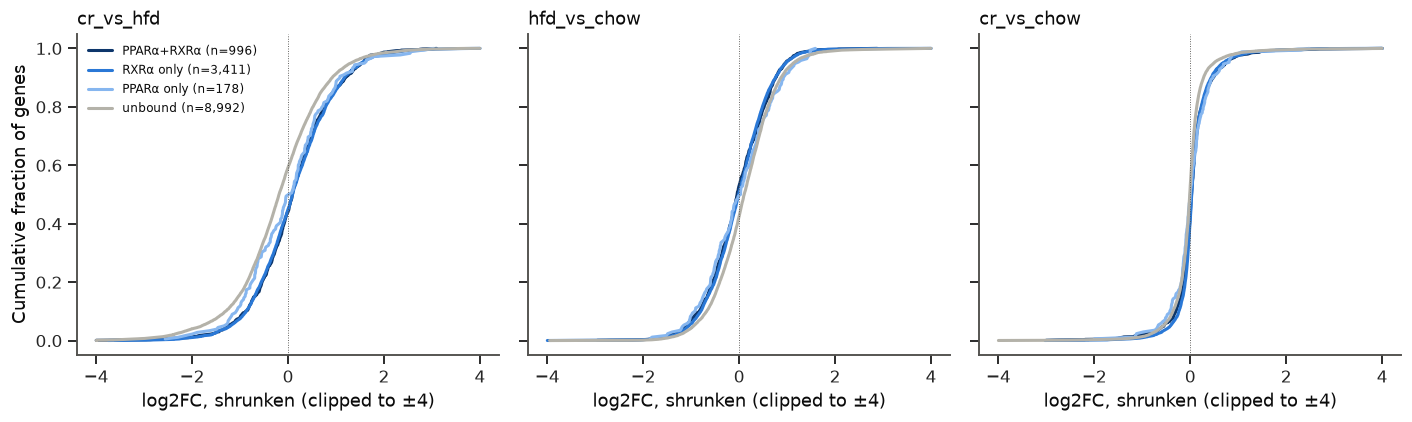

In [17]:
BIND_COL = {"PPARα+RXRα": "#0d366b", "RXRα only": "#2a78d6", "PPARα only": "#86b6ef", "unbound": C_NS}  # one hue, ordinal + neutral
fig, axes = plt.subplots(1, len(CONTRASTS), figsize=(13, 4), sharey=True)
for ax, c in zip(axes, CONTRASTS):
    d = de[c]
    for cls in BIND_ORDER:
        x = np.sort(d.loc[d.binding == cls, "log2FoldChange"].clip(-4, 4))
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=BIND_COL[cls], lw=2, label=f"{cls} (n={len(x):,})")
    ax.axvline(0, color="#52514e", lw=0.6, ls=":")
    ax.set_title(c, loc="left"); ax.set_xlabel("log2FC, shrunken (clipped to ±4)")
axes[0].set_ylabel("Cumulative fraction of genes")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(OUT / "bound_vs_unbound_lfc_ecdf.png", dpi=200); plt.show()

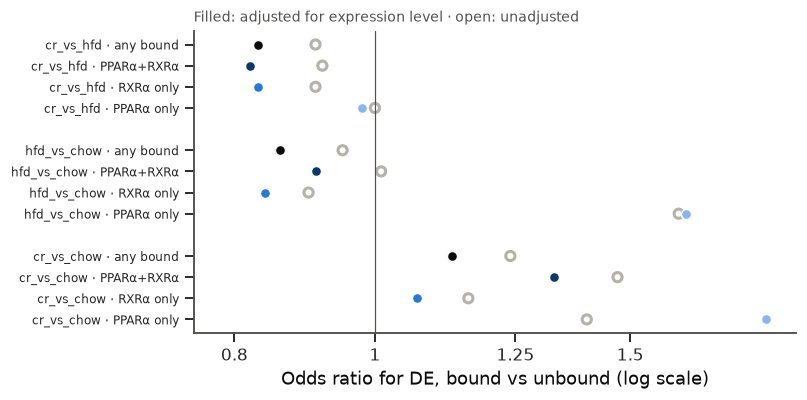

In [18]:
d = enrich[(enrich.outcome == "DE")]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ypos, labels = [], []
for i, (c, g) in enumerate(d.groupby("contrast", sort=False)):
    for j, (_, r) in enumerate(g.iterrows()):
        y = i * (len(g) + 1) + j
        ax.scatter(r["OR"], y, s=36, facecolor="none", edgecolor=C_NS, linewidth=2, zorder=2)
        ax.scatter(r["OR (expr-adjusted, CMH)"], y, s=44, color=BIND_COL.get(r.binding, "#0b0b0b"), edgecolor="#fcfcfb", linewidth=1, zorder=3)
        ypos.append(y); labels.append(f"{c} · {r.binding}")
ax.axvline(1, color="#52514e", lw=0.8)
ax.set_yticks(ypos, labels, fontsize=8); ax.invert_yaxis(); ax.set_xscale("log")
ticks = [0.5, 0.67, 0.8, 1, 1.25, 1.5, 2, 3]
ax.set_xlim(min(0.75, d[["OR", "OR (expr-adjusted, CMH)"]].min().min() * 0.95), max(1.33, d[["OR", "OR (expr-adjusted, CMH)"]].max().max() * 1.05))
ax.xaxis.set_major_locator(plt.FixedLocator(ticks)); ax.xaxis.set_minor_locator(plt.NullLocator())
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Odds ratio for DE, bound vs unbound (log scale)")
ax.set_title("Filled: adjusted for expression level · open: unadjusted", loc="left", fontsize=9, color="#52514e")
fig.tight_layout(); fig.savefig(OUT / "bound_vs_unbound_DE_odds.png", dpi=200); plt.show()

In [19]:
tbl = genes.copy()
for c in CONTRASTS:
    r = rna_all[c][["gene_id", "log2FoldChange", "padj"]].rename(columns={"log2FoldChange": f"{c}_lfc", "padj": f"{c}_padj"})
    tbl = tbl.merge(r, on="gene_id", how="left")
tbl.to_csv(OUT / "gene_binding_vs_expression.tsv", sep="\t", index=False)
print(f"{len(tbl):,} protein-coding genes written to gene_binding_vs_expression.tsv")

21,572 protein-coding genes written to gene_binding_vs_expression.tsv


### Known PPARα targets
All consensus sites within 10 kb of the TSS of canonical hepatic PPARα targets, with RNA-seq results for the gene.

In [20]:
TARGETS = ["Cpt1a", "Acox1", "Pdk4", "Fgf21", "Hmgcs2", "Cyp4a14", "Angptl4", "Ehhadh", "Acadm", "Plin2"]
tg = []
for f, a in ann.items():
    t = a[a.gene_name.isin(TARGETS) & (a.dist_to_tss.abs() <= LINK_DIST)]
    tg.append(t.assign(factor=f)[["factor", "gene_name", "gene_id", "chr", "start", "dist_to_tss", "feature", "Conc", "Fold", "FDR"]])
tg = pd.concat(tg).merge(rna[["gene_id", "log2FoldChange", "padj"]], on="gene_id", how="left")
tg.to_csv(OUT / "ppara_targets.tsv", sep="\t", index=False)
missing = sorted(set(TARGETS) - set(tg.gene_name))
print("No site within 10 kb:", ", ".join(missing) or "none")
tg.sort_values(["gene_name", "factor", "FDR"]).round(3)

No site within 10 kb: Fgf21, Hmgcs2, Plin2


,factor,gene_name,gene_id,chr,start,dist_to_tss,feature,Conc,Fold,FDR,log2FoldChange,padj
4,PPARA,Acadm,ENSMUSG00000062908,3,153653829,-3760,Intergenic,4.023,-0.875,0.363,0.031,0.951
5,PPARA,Acadm,ENSMUSG00000062908,3,153650370,-301,Promoter,5.543,-0.808,0.388,0.031,0.951
7,PPARA,Acadm,ENSMUSG00000062908,3,153652899,-2830,Promoter,4.854,-0.734,0.415,0.031,0.951
12,RXRA,Acadm,ENSMUSG00000062908,3,153653826,-3757,Intergenic,5.210,0.003,1.000,0.031,0.951
13,RXRA,Acadm,ENSMUSG00000062908,3,153649709,174,Promoter,4.014,0.001,1.000,0.031,0.951
16,RXRA,Acadm,ENSMUSG00000062908,3,153650353,-284,Promoter,5.285,-0.000,1.000,0.031,0.951
1,PPARA,Acox1,ENSMUSG00000020777,11,116093636,-3965,Intron,4.409,-1.125,0.292,0.073,0.890
8,RXRA,Acox1,ENSMUSG00000020777,11,116096952,-7281,Exon,2.763,-0.005,1.000,0.073,0.890
15,RXRA,Angptl4,ENSMUSG00000002289,17,33993192,7412,3' UTR,3.240,-0.000,1.000,0.549,0.234
10,RXRA,Cpt1a,ENSMUSG00000024900,19,3386041,2516,Promoter,4.992,0.004,1.000,-0.518,0.194


In [21]:
sorted(p.name for p in OUT.iterdir())

['PPARA.consensus.annotated.tsv',
 'PPARA.db_sig.annotated.tsv',
 'RXRA.consensus.annotated.tsv',
 'RXRA.db_sig.annotated.tsv',
 'bound_vs_unbound_DE_enrichment.tsv',
 'bound_vs_unbound_DE_odds.png',
 'bound_vs_unbound_lfc_ecdf.png',
 'distance_to_tss.png',
 'feature_distribution.png',
 'gene_binding_vs_expression.tsv',
 'gtf_features.pkl',
 'ppara_targets.tsv']